In [1]:
from pathlib import Path
import os
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Image
%matplotlib inline
ROOT = Path.cwd().parent
DATA = ROOT / 'data'
OUT = ROOT / 'results'
OUT.mkdir(exist_ok=True)
RAW = Path(os.environ.get('ASTRO320W_DATA', '/Users/gracedavis/2026-10-19_before_submission_cleanup'))
BIAS = Path(os.environ.get('ASTRO320W_BIAS', '/Users/gracedavis/ASTRO 320W/04_Data/A/Bias_Frames'))


In [2]:
from astropy.io import fits
import numpy as np
import matplotlib.pyplot as plt
import astroalign as aa

folder = str(RAW / 'EXERCISE C-2')

files = [
    f"{folder}/Ogma-{i:04d}.fit"
    for i in range(1, 16)
]

print("Number of images:", len(files))

for f in files:
    print(f)

Number of images: 15
/Users/gracedavis/2026-10-19_before_submission_cleanup/EXERCISE C-2/Ogma-0001.fit
/Users/gracedavis/2026-10-19_before_submission_cleanup/EXERCISE C-2/Ogma-0002.fit
/Users/gracedavis/2026-10-19_before_submission_cleanup/EXERCISE C-2/Ogma-0003.fit
/Users/gracedavis/2026-10-19_before_submission_cleanup/EXERCISE C-2/Ogma-0004.fit
/Users/gracedavis/2026-10-19_before_submission_cleanup/EXERCISE C-2/Ogma-0005.fit
/Users/gracedavis/2026-10-19_before_submission_cleanup/EXERCISE C-2/Ogma-0006.fit
/Users/gracedavis/2026-10-19_before_submission_cleanup/EXERCISE C-2/Ogma-0007.fit
/Users/gracedavis/2026-10-19_before_submission_cleanup/EXERCISE C-2/Ogma-0008.fit
/Users/gracedavis/2026-10-19_before_submission_cleanup/EXERCISE C-2/Ogma-0009.fit
/Users/gracedavis/2026-10-19_before_submission_cleanup/EXERCISE C-2/Ogma-0010.fit
/Users/gracedavis/2026-10-19_before_submission_cleanup/EXERCISE C-2/Ogma-0011.fit
/Users/gracedavis/2026-10-19_before_submission_cleanup/EXERCISE C-2/Ogma-0012

In [3]:
reference = fits.getdata(files[0]).astype(float)

aligned_images = [reference]

print("Ogma-0001: reference")

for i, filename in enumerate(files[1:], start=2):

    image = fits.getdata(filename).astype(float)

    try:
        aligned, footprint = aa.register(
            image,
            reference
        )

        aligned_images.append(aligned)

        print(f"Ogma-{i:04d}: aligned")

    except Exception as e:
        print(f"Ogma-{i:04d}: FAILED")
        print(e)

aligned_images = np.array(aligned_images)

print("\nSuccessfully aligned:", len(aligned_images))

Ogma-0001: reference


Ogma-0002: aligned


Ogma-0003: aligned


Ogma-0004: aligned


Ogma-0005: aligned


...

Ogma-0011: aligned


Ogma-0012: aligned


Ogma-0013: aligned


Ogma-0014: aligned


Ogma-0015: aligned

Successfully aligned: 15


In [4]:
master_ogma = np.nanmedian(aligned_images, axis=0)

print("Stacked image shape:", master_ogma.shape)

Stacked image shape: (1528, 1528)


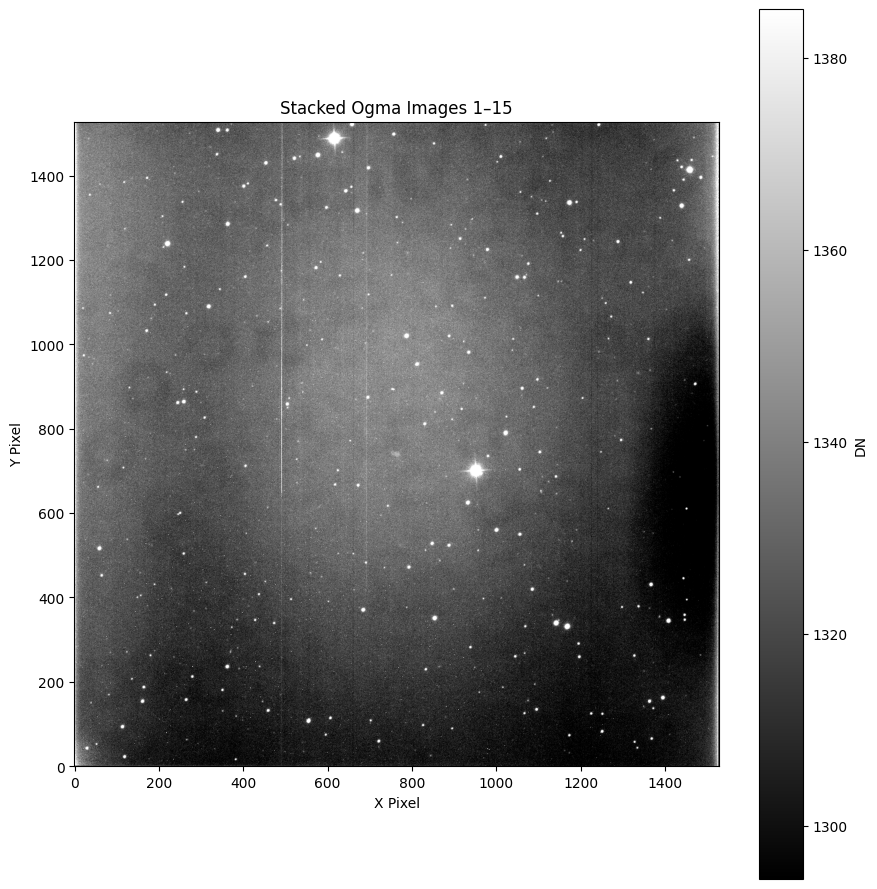

In [5]:
vmin = np.nanpercentile(master_ogma, 5)
vmax = np.nanpercentile(master_ogma, 99.5)

plt.figure(figsize=(9, 9))

plt.imshow(
    master_ogma,
    origin="lower",
    cmap="gray",
    vmin=vmin,
    vmax=vmax
)

plt.colorbar(label="DN")
plt.xlabel("X Pixel")
plt.ylabel("Y Pixel")
plt.title("Stacked Ogma Images 1–15")

plt.tight_layout()
plt.show()